# Human Only Pair

## 1. Setup

We use NumPy, pandas and Matplotlib, which are available in Colab. Velocity and error are reported in stored units. Physical forward and left axis labels have not been independently verified.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from google.colab import drive

drive.mount('/content/drive')
BASE = Path('/content/drive/MyDrive/RadaVis')
INPUTS = BASE / 'data'
PREDICTIONS = BASE / 'results/main_0/phase1_finish_cache'
RECORDINGS = [
    'bot_beckman_5thfloor_1', 'bot_csl_4thfloor_0',
    'cart_csl_basement_2', 'cart_csl_upper_1',
    'walk_csl_basement_4', 'walk_csl_groundfloor_1',
]
ANCHOR = RECORDINGS[0]
SOURCE_COMMIT = 'cbcb6439b89c068d86a424215ee61edc925191ae'
STAMP = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
OUT = BASE / 'results/main_0/phase1_submission' / STAMP
OUT.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({'font.size': 10, 'axes.grid': False})
COLOURS = {'bot': '#0072B2', 'cart': '#D55E00', 'walk': '#009E73'}

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def table(name, frame, show=True):
    frame.to_csv(OUT / f'{name}.csv', index=False)
    if show:
        display(frame.round(4))

def figure(name, fig):
    fig.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def runs(part):
    part = part.sort_values('sample')
    labels = part['sample'].diff().ne(1).cumsum()
    return part.groupby(labels).agg(
        first_sample=('sample', 'min'), last_sample=('sample', 'max'),
        samples=('sample', 'size'), median_error=('vector_error', 'median'),
    ).reset_index(drop=True)

print('Output folder:', OUT)

Mounted at /content/drive
Output folder: /content/drive/MyDrive/RadaVis/results/main_0/phase1_submission/20261026T093910_289317Z


## 2. Load and validate the completed evaluations

Each prediction file must match its recorded digest, the input timestamps and the first two reference velocity components. All six files must identify the same source revision, checkpoint, configuration and inference script. These checks establish alignment with the saved evaluation. They do not independently verify physical calibration or the accuracy of the reference measurements.

For each frame, signed error is prediction minus reference. Vector error is the Euclidean length of the two component errors, and speed is the length of the reference velocity vector. We retain every frame in the overall evaluation.

In [ ]:
required = [p for rec in RECORDINGS for p in (
    INPUTS / f'{rec}.npz', PREDICTIONS / f'{rec}.npz',
    PREDICTIONS / f'{rec}.json',
)]
missing = [str(p) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError(
        'Restore the completed data and prediction cache folders, or update BASE. '
        'Missing files:\n' + '\n'.join(missing)
    )

frames, provenance = {}, {}
identity_keys = ['source_commit', 'checkpoint_sha256', 'config_sha256', 'script_sha256']
for rec in RECORDINGS:
    prediction_path = PREDICTIONS / f'{rec}.npz'
    info = json.loads((PREDICTIONS / f'{rec}.json').read_text())
    assert all(info.get(k) for k in identity_keys), f'Incomplete provenance: {rec}'
    assert info['source_commit'] == SOURCE_COMMIT, f'Unexpected source: {rec}'
    assert info.get('prediction_sha256') == sha256(prediction_path), rec
    with np.load(INPUTS / f'{rec}.npz', allow_pickle=False) as source:
        time = source['time'].reshape(-1).astype(float)
        reference = source['velo_gt'][:, :2].astype(float)
    with np.load(prediction_path, allow_pickle=False) as saved:
        prediction = np.column_stack([saved['flow_pred_xs'].reshape(-1),
                                      saved['flow_pred_ys'].reshape(-1)]).astype(float)
        saved_reference = np.column_stack([saved['flow_gt_xs'].reshape(-1),
                                           saved['flow_gt_ys'].reshape(-1)])
        np.testing.assert_allclose(saved['time'].reshape(-1), time, rtol=0, atol=1e-6)
    assert len(time) > 10 and reference.shape == prediction.shape == saved_reference.shape
    assert reference.shape == (len(time), 2) and np.all(np.diff(time) > 0)
    assert all(np.isfinite(a).all() for a in [time, reference, prediction, saved_reference])
    np.testing.assert_allclose(saved_reference, reference, rtol=1e-5, atol=1e-6)
    error = prediction - reference
    frames[rec] = pd.DataFrame({
        'recording': rec, 'group': rec.split('_')[0], 'sample': np.arange(len(time)),
        'elapsed': time - time[0], 'gt_x': reference[:, 0], 'gt_y': reference[:, 1],
        'pred_x': prediction[:, 0], 'pred_y': prediction[:, 1],
        'error_x': error[:, 0], 'error_y': error[:, 1],
        'speed': np.linalg.norm(reference, axis=1),
        'vector_error': np.linalg.norm(error, axis=1),
        'angle_deg': (np.degrees(np.arctan2(reference[:, 1], reference[:, 0])) + 180) % 360 - 180,
    })
    provenance[rec] = info
for key in identity_keys:
    assert len({p[key] for p in provenance.values()}) == 1, f'Mixed evaluation identity: {key}'
combined = pd.concat(frames.values(), ignore_index=True)
table('frame_evaluation', combined, show=False)
print(f'Validated {len(frames)} recordings and {len(combined):,} frames.')

Validated 6 recordings and 10,749 frames.


## 3. Reference and predicted velocity

Each row is one recording. The two columns show the numerical x and y components using the same time axis within that recording. We look for sustained disagreements and reference changes that the prediction follows weakly. A missed reference spike alone does not establish a delay, because the reference is itself processed.

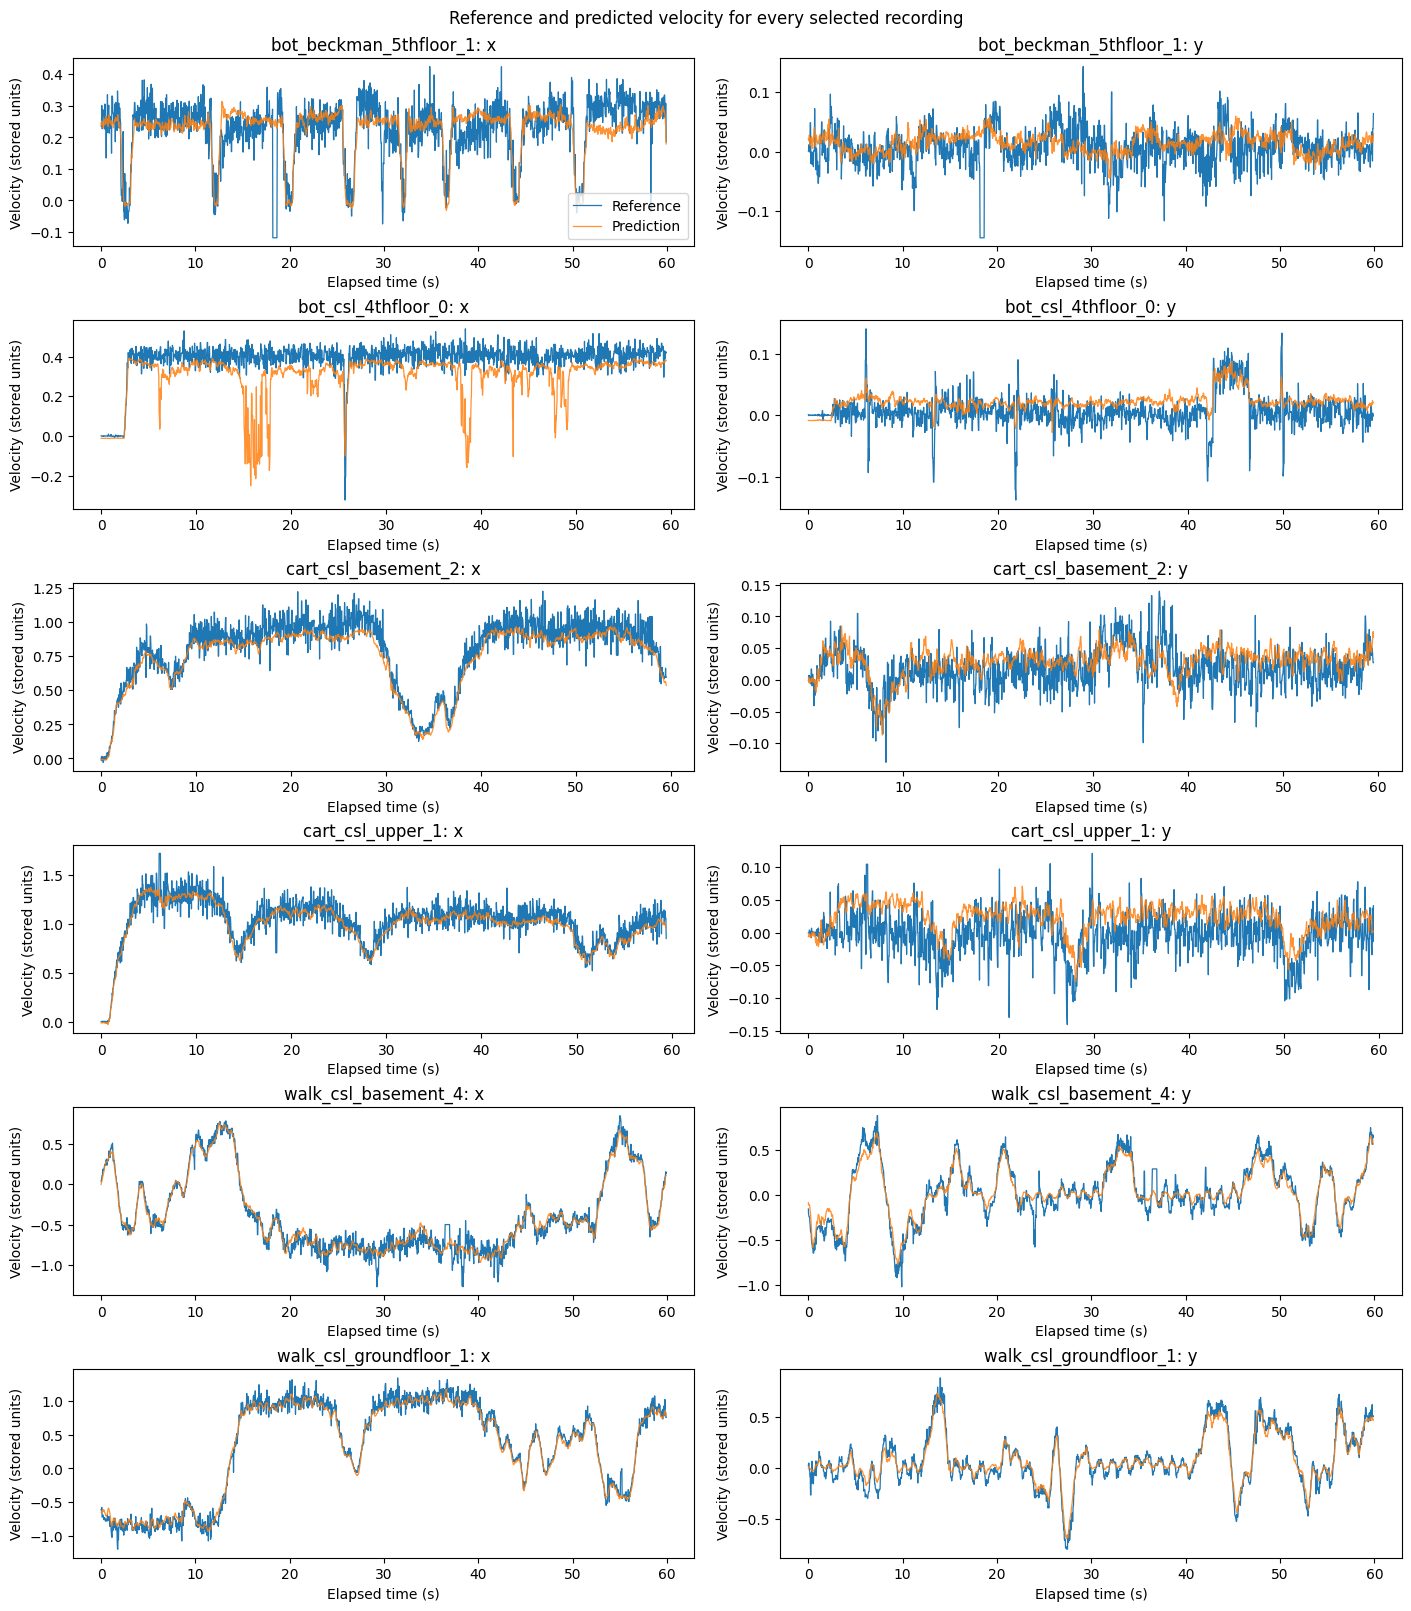

In [ ]:
fig, axes = plt.subplots(6, 2, figsize=(14, 16), constrained_layout=True)
for row, rec in enumerate(RECORDINGS):
    d = frames[rec]
    for col, axis in enumerate(['x', 'y']):
        ax = axes[row, col]
        ax.plot(d['elapsed'], d[f'gt_{axis}'], lw=0.9, label='Reference')
        ax.plot(d['elapsed'], d[f'pred_{axis}'], lw=0.9, alpha=0.85, label='Prediction')
        ax.set(title=f'{rec}: {axis}', xlabel='Elapsed time (s)', ylabel='Velocity (stored units)')
axes[0, 0].legend(loc='best')
fig.suptitle('Reference and predicted velocity for every selected recording')
figure('01_velocity', fig)

## 4. Error distributions and large disagreements

MAE measures typical absolute component error. RMSE gives more weight to large errors. Signed bias shows average overestimation or underestimation. Error standard deviation should be read beside reference standard deviation, since the two components can have different movement ranges.

The cumulative distributions show the fraction of frames at or below each vector error. We also count errors above 0.1 and 0.2 stored units. These are descriptive thresholds, not validated definitions of model failure. Neighbouring frames are related, so frame counts are not counts of independent trials.

,recording,group,frames,median_error,mean_error,p95_error,median_speed,repeated_reference_pct
0,bot_beckman_5thfloor_1,bot,1798,0.0506,0.0591,0.1212,0.2430,27.3790
1,bot_csl_4thfloor_0,bot,1785,0.0715,0.0974,0.3098,0.4081,27.0740
2,cart_csl_basement_2,cart,1786,0.0722,0.0850,0.1992,0.8850,27.4510
3,cart_csl_upper_1,cart,1784,0.0823,0.0933,0.2045,1.0705,27.7622
4,walk_csl_basement_4,walk,1798,0.0936,0.1091,0.2328,0.6810,27.7685
5,walk_csl_groundfloor_1,walk,1798,0.0887,0.0965,0.2001,0.8228,27.4346


,recording,axis,bias,MAE,RMSE,error_SD,reference_SD
0,bot_beckman_5thfloor_1,x,-0.0022,0.0484,0.0667,0.0666,0.0959
1,bot_beckman_5thfloor_1,y,0.0059,0.0250,0.0346,0.0341,0.0326
2,bot_csl_4thfloor_0,x,-0.0867,0.0914,0.1372,0.1063,0.0970
3,bot_csl_4thfloor_0,y,0.0154,0.0210,0.0267,0.0218,0.0272
4,cart_csl_basement_2,x,-0.0590,0.0767,0.0976,0.0777,0.2544
5,cart_csl_basement_2,y,0.0101,0.0252,0.0323,0.0307,0.0317
6,cart_csl_upper_1,x,-0.0415,0.0823,0.1041,0.0954,0.2400
7,cart_csl_upper_1,y,0.0261,0.0323,0.0392,0.0292,0.0324
8,walk_csl_basement_4,x,-0.0008,0.0664,0.0920,0.0920,0.4716
9,walk_csl_basement_4,y,0.0058,0.0721,0.0943,0.0941,0.3191


,recording,threshold,frames_above,percent_above,contiguous_runs,longest_run_frames
0,bot_beckman_5thfloor_1,0.1,214,11.9021,140,14
1,bot_beckman_5thfloor_1,0.2,19,1.0567,5,14
2,bot_csl_4thfloor_0,0.1,528,29.5798,174,64
3,bot_csl_4thfloor_0,0.2,141,7.8992,25,18
4,cart_csl_basement_2,0.1,584,32.6988,258,9
5,cart_csl_basement_2,0.2,88,4.9272,61,3
6,cart_csl_upper_1,0.1,644,36.0987,274,12
7,cart_csl_upper_1,0.2,98,5.4933,69,5
8,walk_csl_basement_4,0.1,822,45.7175,263,24
9,walk_csl_basement_4,0.2,156,8.6763,80,15


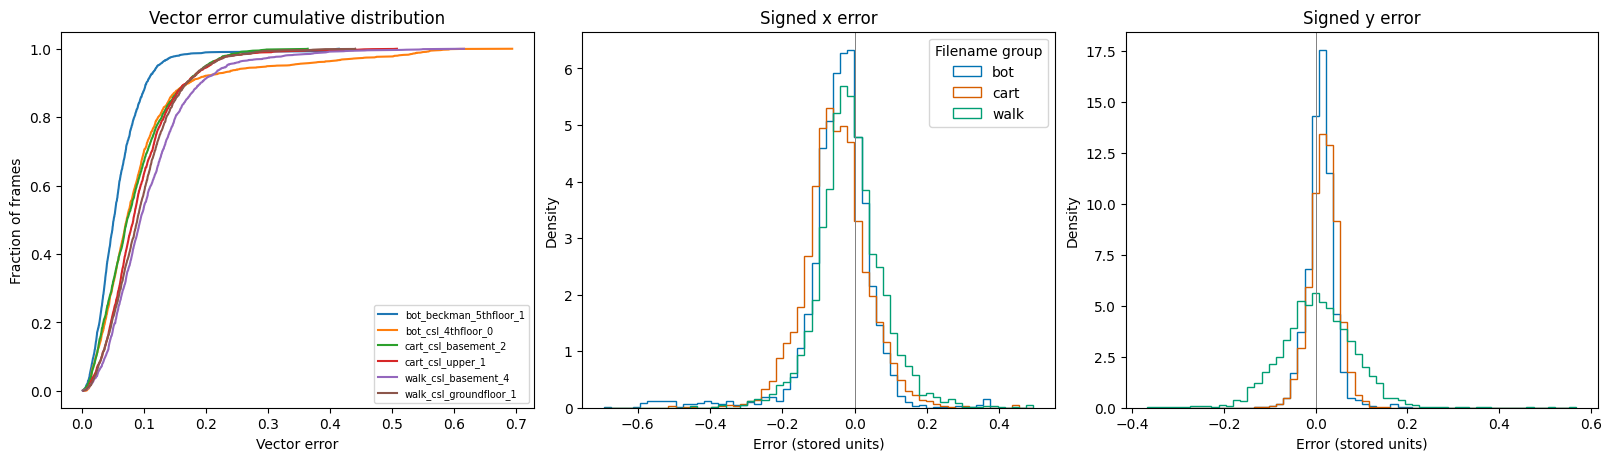

In [ ]:
summary_rows, component_rows, tail_rows = [], [], []
for rec, d in frames.items():
    repeated = np.all(np.diff(d[['gt_x', 'gt_y']].to_numpy(), axis=0) == 0, axis=1)
    summary_rows.append({
        'recording': rec, 'group': d['group'].iat[0], 'frames': len(d),
        'median_error': d['vector_error'].median(), 'mean_error': d['vector_error'].mean(),
        'p95_error': d['vector_error'].quantile(0.95), 'median_speed': d['speed'].median(),
        'repeated_reference_pct': 100 * repeated.mean(),
    })
    for axis in ['x', 'y']:
        e = d[f'error_{axis}']
        component_rows.append({
            'recording': rec, 'axis': axis, 'bias': e.mean(), 'MAE': e.abs().mean(),
            'RMSE': np.sqrt(np.mean(e ** 2)), 'error_SD': e.std(ddof=0),
            'reference_SD': d[f'gt_{axis}'].std(ddof=0),
        })
    for threshold in [0.1, 0.2]:
        selected = d[d['vector_error'] > threshold]
        events = runs(selected)
        tail_rows.append({
            'recording': rec, 'threshold': threshold, 'frames_above': len(selected),
            'percent_above': 100 * len(selected) / len(d), 'contiguous_runs': len(events),
            'longest_run_frames': int(events['samples'].max()) if len(events) else 0,
        })
summary = pd.DataFrame(summary_rows)
components = pd.DataFrame(component_rows)
tails = pd.DataFrame(tail_rows)
table('recording_summary', summary)
table('component_metrics', components)
table('error_tail_counts', tails)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for rec, d in frames.items():
    values = np.sort(d['vector_error'].to_numpy())
    axes[0].plot(values, np.arange(1, len(values) + 1) / len(values), label=rec)
for ax, axis in zip(axes[1:], ['x', 'y']):
    edges = np.histogram_bin_edges(combined[f'error_{axis}'], bins=60)
    for group, colour in COLOURS.items():
        values = combined.loc[combined['group'] == group, f'error_{axis}']
        ax.hist(values, bins=edges, density=True, histtype='step', color=colour, label=group)
    ax.axvline(0, color='grey', lw=0.7)
    ax.set(title=f'Signed {axis} error', xlabel='Error (stored units)', ylabel='Density')
axes[0].set(title='Vector error cumulative distribution', xlabel='Vector error', ylabel='Fraction of frames')
axes[0].legend(fontsize=7, loc='lower right')
axes[1].legend(title='Filename group')
figure('02_error_distributions', fig)

## 5. Error versus motion speed

All recordings use the same eight speed bins. Points show individual frames and the line joins median errors in occupied bins. Counts are printed in each panel; an empty bin has no evidence. A rise in error with speed is an association and may also reflect direction, scene or reference processing.

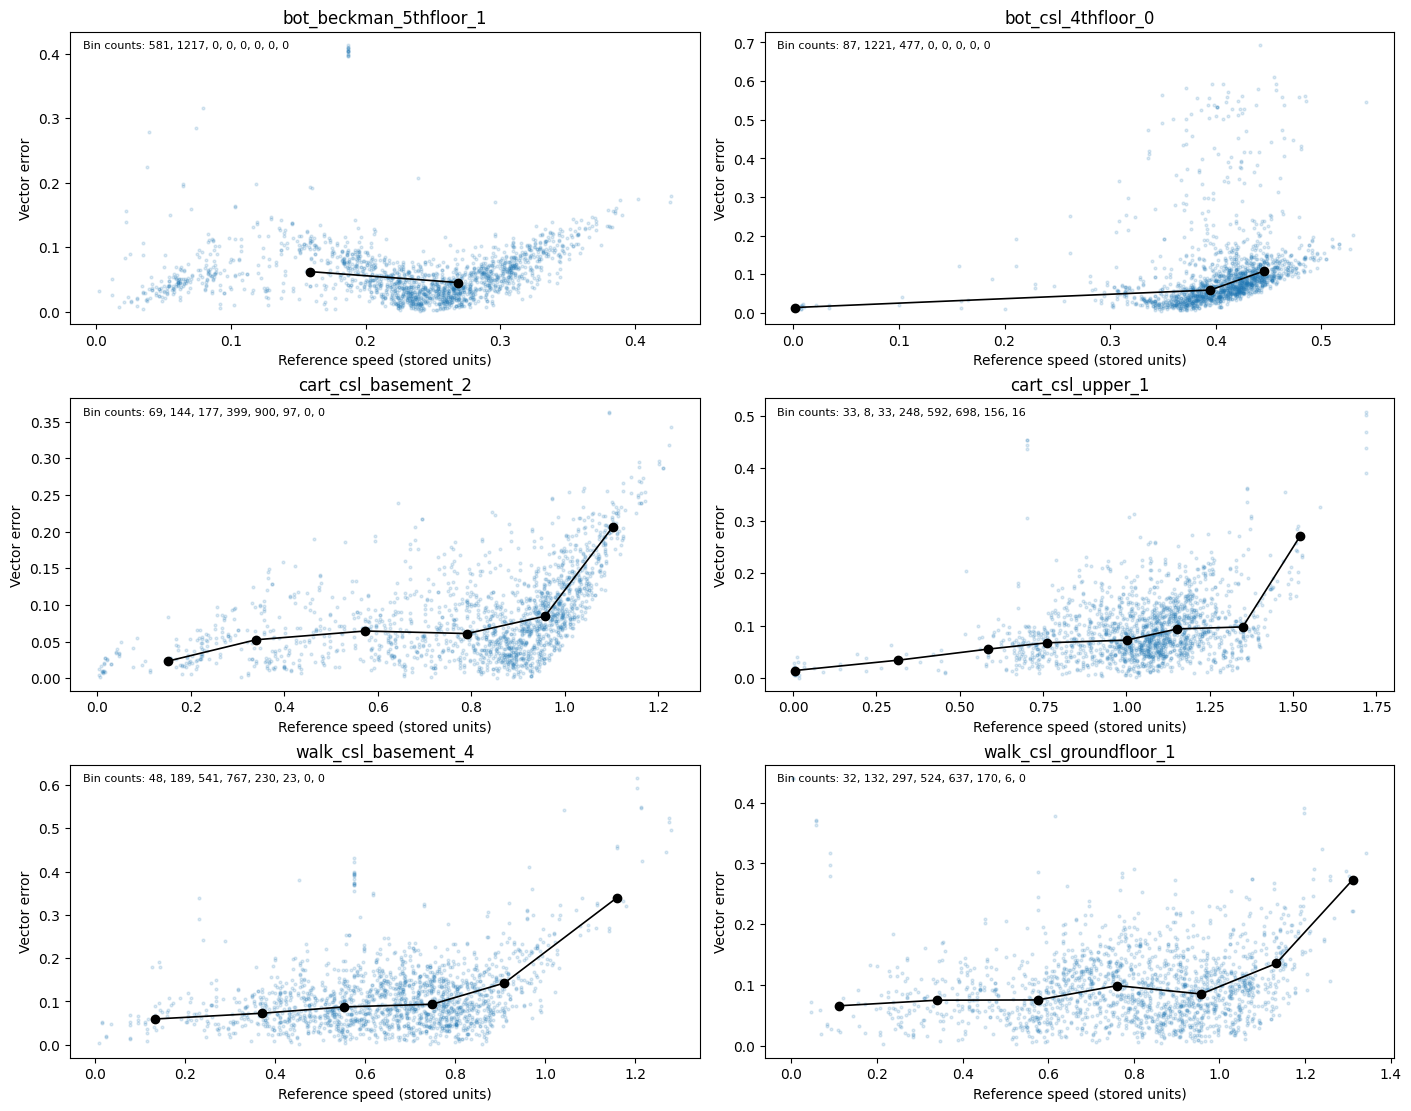

,bin,lower,upper
0,0,0.0000,0.2148
1,1,0.2148,0.4296
2,2,0.4296,0.6444
3,3,0.6444,0.8592
4,4,0.8592,1.0740
5,5,1.0740,1.2889
6,6,1.2889,1.5037
7,7,1.5037,1.7185


In [ ]:
speed_edges = np.linspace(0, float(combined['speed'].max()) + 1e-9, 9)
speed_rows = []
fig, axes = plt.subplots(3, 2, figsize=(14, 11), constrained_layout=True)
for ax, rec in zip(axes.flat, RECORDINGS):
    d = frames[rec].copy()
    d['speed_bin'] = pd.cut(d['speed'], speed_edges, labels=False, include_lowest=True)
    b = d.groupby('speed_bin', observed=True).agg(
        frames=('vector_error', 'size'), median_speed=('speed', 'median'),
        median_error=('vector_error', 'median'),
    ).reindex(range(8))
    b['frames'] = b['frames'].fillna(0).astype(int)
    b['recording'] = rec
    speed_rows.append(b.reset_index())
    ax.scatter(d['speed'], d['vector_error'], s=4, alpha=0.15)
    ax.plot(b['median_speed'], b['median_error'], marker='o', color='black', lw=1.2)
    ax.set(title=rec, xlabel='Reference speed (stored units)', ylabel='Vector error')
    ax.text(0.02, 0.97, 'Bin counts: ' + ', '.join(map(str, b['frames'])),
            transform=ax.transAxes, va='top', fontsize=8)
speed_summary = pd.concat(speed_rows, ignore_index=True)
figure('03_error_vs_speed', fig)
table('speed_bins', speed_summary, show=False)
table('speed_bin_edges', pd.DataFrame({'bin': range(8), 'lower': speed_edges[:-1], 'upper': speed_edges[1:]}))

## 6. Error versus motion direction

Direction is calculated with `atan2(reference_y, reference_x)` in the numerical local frame. We use eight sectors of 45 degrees. Speed must exceed 0.05 stored units in the main view, because direction becomes unstable near zero speed. We also recalculate at 0.025 and 0.075. These cutoffs are exploratory.

Each bar includes its frame count. We trace contiguous intervals in each sector to check whether a large median is supported by repeated events or dominated by one interval. A contiguous run is a description of timing, not proof of an independent event.

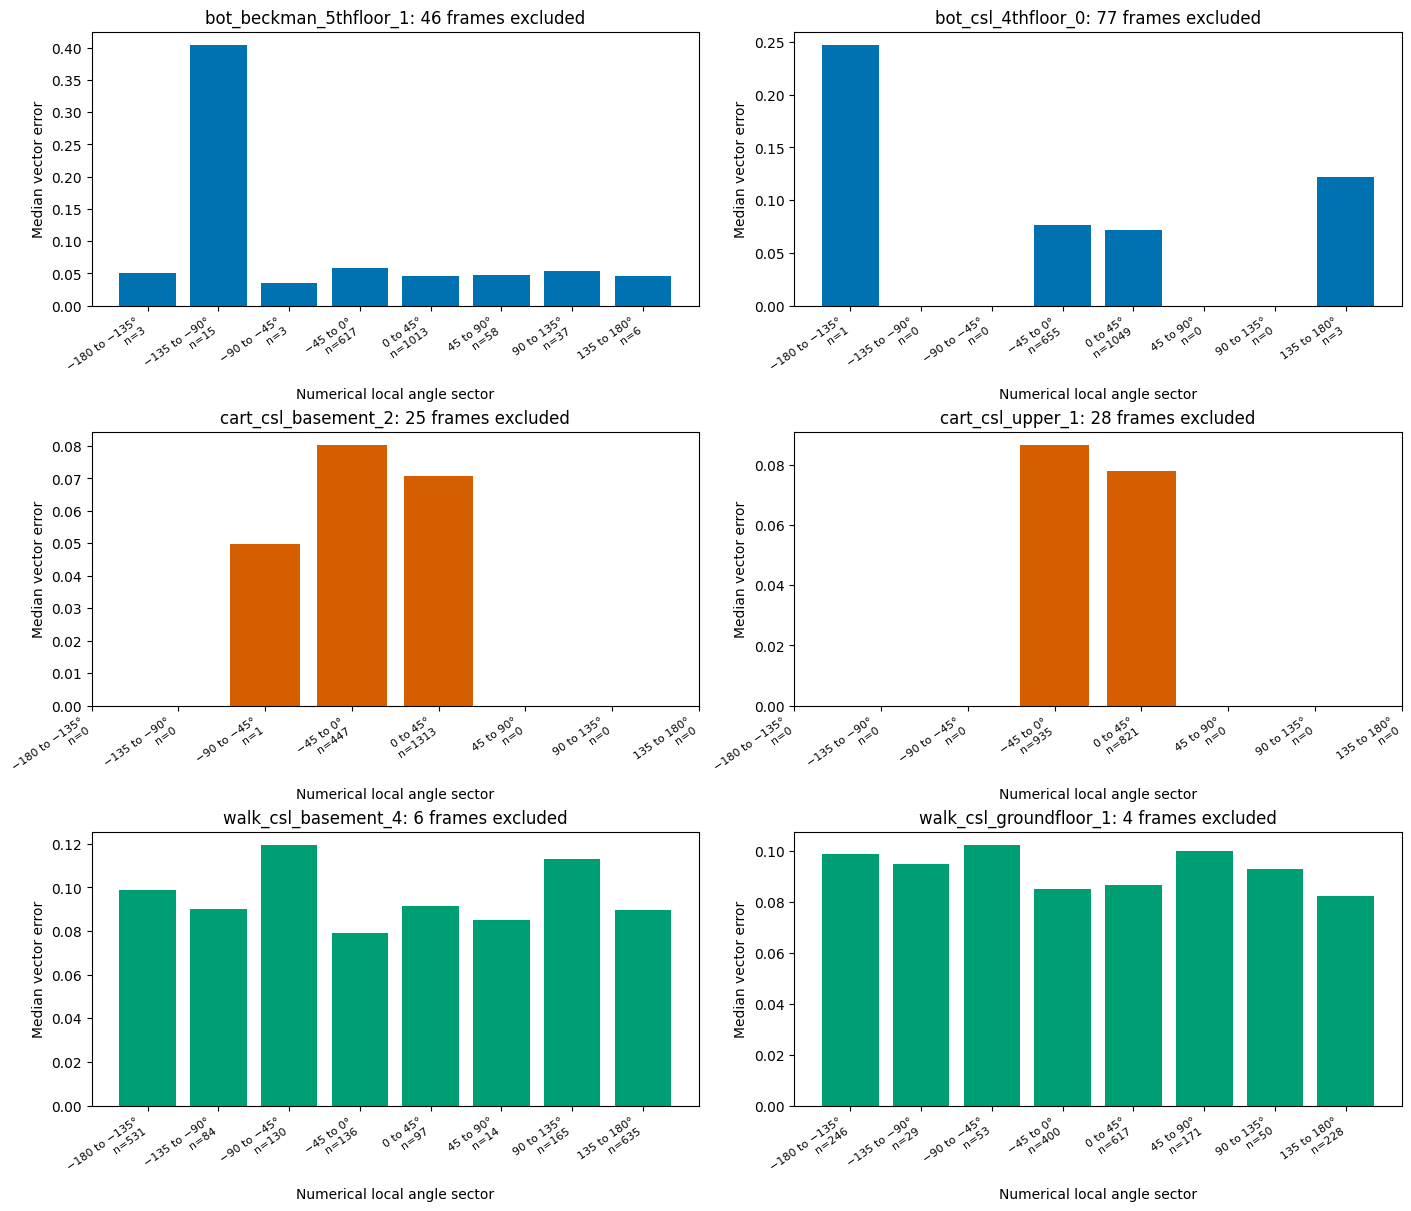

,recording,angle_degrees,frames,median_error,runs,largest_run_fraction,run_start,run_end
0,bot_beckman_5thfloor_1,−135 to −90,15,0.4048,2,0.9333,546.0,559.0
1,bot_csl_4thfloor_0,−180 to −135,1,0.2473,1,1.0000,770.0,770.0
2,cart_csl_basement_2,−45 to 0,447,0.0804,181,0.1051,192.0,238.0
3,cart_csl_upper_1,−45 to 0,935,0.0867,228,0.0930,1493.0,1579.0
4,walk_csl_basement_4,−90 to −45,130,0.1196,14,0.2308,271.0,300.0
5,walk_csl_groundfloor_1,−90 to −45,53,0.1023,5,0.3774,817.0,836.0


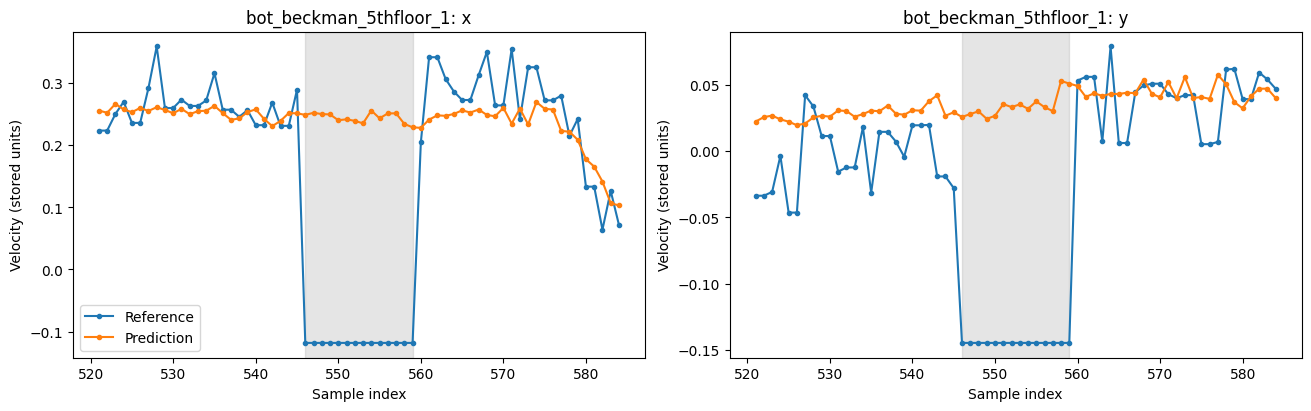

,cutoff,frames,median_error,largest_run_fraction,run_start,run_end
1,0.025,16,0.4044,0.8750,546.0,559.0
9,0.050,15,0.4048,0.9333,546.0,559.0
17,0.075,15,0.4048,0.9333,546.0,559.0


In [ ]:
direction_rows = []
sector_edges = np.linspace(-180, 180, 9)
sector_labels = [f'{int(a)} to {int(b)}'.replace('-', '−')
                 for a, b in zip(sector_edges[:-1], sector_edges[1:])]
for rec, d in frames.items():
    for cutoff in [0.025, 0.05, 0.075]:
        active = d[d['speed'] > cutoff].copy()
        active['sector'] = pd.cut(active['angle_deg'], sector_edges, labels=False, right=False)
        for sector in range(8):
            part = active[active['sector'] == sector]
            intervals = runs(part)
            largest = intervals.sort_values('samples', ascending=False).iloc[0] if len(intervals) else None
            direction_rows.append({
                'recording': rec, 'cutoff': cutoff, 'sector': sector,
                'angle_degrees': sector_labels[sector], 'frames': len(part),
                'excluded_frames': len(d) - len(active), 'median_error': part['vector_error'].median(),
                'median_speed': part['speed'].median(), 'runs': len(intervals),
                'largest_run_fraction': largest['samples'] / len(part) if len(part) else np.nan,
                'run_start': int(largest['first_sample']) if len(part) else np.nan,
                'run_end': int(largest['last_sample']) if len(part) else np.nan,
            })
direction = pd.DataFrame(direction_rows)
main_direction = direction[direction['cutoff'] == 0.05].copy()
fig, axes = plt.subplots(3, 2, figsize=(14, 12), constrained_layout=True)
for ax, rec in zip(axes.flat, RECORDINGS):
    b = main_direction[main_direction['recording'] == rec]
    ax.bar(np.arange(8), b['median_error'], color=COLOURS[rec.split('_')[0]])
    ax.set_xticks(np.arange(8), [f'{angle}°\nn={n}' for angle, n in zip(b['angle_degrees'], b['frames'])],
                  rotation=35, ha='right', fontsize=8)
    ax.set(title=f"{rec}: {b['excluded_frames'].iat[0]} frames excluded",
           xlabel='Numerical local angle sector', ylabel='Median vector error')
figure('04_error_vs_direction', fig)
table('direction_sensitivity_and_runs', direction, show=False)

worst_sectors = main_direction.dropna(subset=['median_error']).sort_values('median_error', ascending=False)
worst_sectors = worst_sectors.groupby('recording', sort=False).head(1).set_index('recording').reindex(RECORDINGS).reset_index()
table('largest_error_sector_per_recording', worst_sectors[[
    'recording', 'angle_degrees', 'frames', 'median_error', 'runs',
    'largest_run_fraction', 'run_start', 'run_end',
]])
focus = worst_sectors.set_index('recording').loc[ANCHOR]
start, end = int(focus['run_start']), int(focus['run_end'])
window = frames[ANCHOR].iloc[max(0, start - 25):end + 26]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for ax, axis in zip(axes, ['x', 'y']):
    ax.plot(window['sample'], window[f'gt_{axis}'], marker='.', label='Reference')
    ax.plot(window['sample'], window[f'pred_{axis}'], marker='.', label='Prediction')
    ax.axvspan(start, end, color='grey', alpha=0.2)
    ax.set(title=f'{ANCHOR}: {axis}', xlabel='Sample index', ylabel='Velocity (stored units)')
axes[0].legend()
figure('05_direction_interval_trace', fig)

anchor_sectors = direction[(direction['recording'] == ANCHOR) & (direction['sector'] == focus['sector'])]
table('anchor_direction_cutoff_check', anchor_sectors[[
    'cutoff', 'frames', 'median_error', 'largest_run_fraction', 'run_start', 'run_end',
]])

## 7. Comparison across recording groups

The prefixes `bot`, `cart` and `walk` suggest robot, cart and handheld platforms, but the per file mapping has not been independently verified. We therefore label the comparison using the literal filename groups.

Each point in the left panel represents one recording. The black line is the median of the two recording medians, giving recordings equal weight. The right panel compares bin medians within the common speed ranges from Section 5. There are only two recordings per group, and speed, scene and motion coverage differ. This is a descriptive comparison, rather than an isolated platform effect.

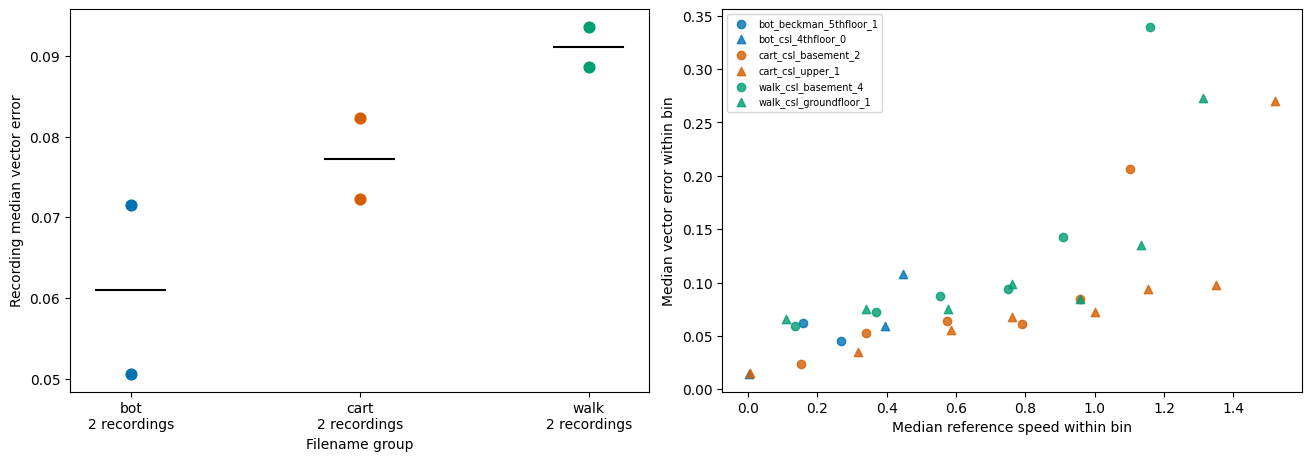

,group,recordings,median_of_recording_medians,minimum_recording_median,maximum_recording_median
0,bot,2,0.0610,0.0506,0.0715
1,cart,2,0.0772,0.0722,0.0823
2,walk,2,0.0911,0.0887,0.0936


In [ ]:
group_summary = summary.groupby('group', sort=True).agg(
    recordings=('recording', 'size'), median_of_recording_medians=('median_error', 'median'),
    minimum_recording_median=('median_error', 'min'), maximum_recording_median=('median_error', 'max'),
).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for i, (group, colour) in enumerate(COLOURS.items()):
    part = summary[summary['group'] == group]
    axes[0].scatter(np.full(len(part), i), part['median_error'], color=colour, s=60)
    axes[0].plot([i - 0.15, i + 0.15], [part['median_error'].median()] * 2, color='black')
    for j, rec in enumerate(part['recording']):
        bins = speed_summary[(speed_summary['recording'] == rec) & (speed_summary['frames'] > 0)]
        axes[1].scatter(bins['median_speed'], bins['median_error'], color=colour,
                        marker=['o', '^'][j], alpha=0.8, label=rec)
axes[0].set_xticks(range(3), [f'{g}\n2 recordings' for g in COLOURS])
axes[0].set(xlabel='Filename group', ylabel='Recording median vector error')
axes[1].set(xlabel='Median reference speed within bin', ylabel='Median vector error within bin')
axes[1].legend(fontsize=7)
figure('06_recording_groups', fig)
table('filename_group_summary', group_summary)

## 8. Radar inputs for lower and higher error

We select one comparison per recording. Higher error candidates are in the largest 10 percent of vector errors; lower error candidates are in the smallest 25 percent. We choose the largest error candidate with a lower error match within `max(0.005, min(0.05, 0.10 × candidate speed))` stored speed units. Frames must be separated by at least 50 sample indices. These are exploratory selection rules and do not guarantee independence.

An unmatched recording is reported explicitly. A speed match does not control scene or direction, so we also report the angular difference. Direction near zero speed remains unreliable. We inspect `radar_d` and `radar_de` separately, each stored as a single channel on a 60 by 181 grid. The colour scale for each array is shared across all selected recordings. Axes show array indices because physical calibration has not been verified.

To go beyond selected images, we also calculate the Spearman association of frame mean intensity and intensity standard deviation with vector error across every frame in each recording. These are descriptive input features, and their correlations can be confounded by motion and scene.

,recording,matched,low_sample,high_sample,low_speed,high_speed,low_error,high_error,speed_gap,tolerance,angle_gap_degrees
0,bot_beckman_5thfloor_1,True,100,554,0.1853,0.1868,0.0201,0.4137,0.0015,0.0187,133.6126
1,bot_csl_4thfloor_0,True,120,472,0.4231,0.4415,0.0365,0.6933,0.0184,0.0442,1.7047
2,cart_csl_basement_2,True,1294,881,0.9879,1.0085,0.0390,0.2544,0.0206,0.0500,0.7532
3,cart_csl_upper_1,True,1625,553,0.7085,0.7023,0.0194,0.4542,0.0061,0.0500,1.3292
4,walk_csl_basement_4,True,1454,1108,0.5751,0.5755,0.0540,0.4305,0.0004,0.0500,18.4830
5,walk_csl_groundfloor_1,True,1569,421,0.6171,0.6158,0.0364,0.3784,0.0014,0.0500,102.0582


,recording,channel,intensity_mean_error_rho,intensity_SD_error_rho
0,bot_beckman_5thfloor_1,radar_d,0.0234,0.0960
1,bot_beckman_5thfloor_1,radar_de,0.0218,0.0841
2,bot_csl_4thfloor_0,radar_d,0.2743,0.1274
3,bot_csl_4thfloor_0,radar_de,0.2724,0.1166
4,cart_csl_basement_2,radar_d,0.0516,0.1747
5,cart_csl_basement_2,radar_de,0.0267,0.1822
6,cart_csl_upper_1,radar_d,0.0293,0.1093
7,cart_csl_upper_1,radar_de,0.0068,0.1027
8,walk_csl_basement_4,radar_d,0.1060,0.1212
9,walk_csl_basement_4,radar_de,0.1221,0.1089


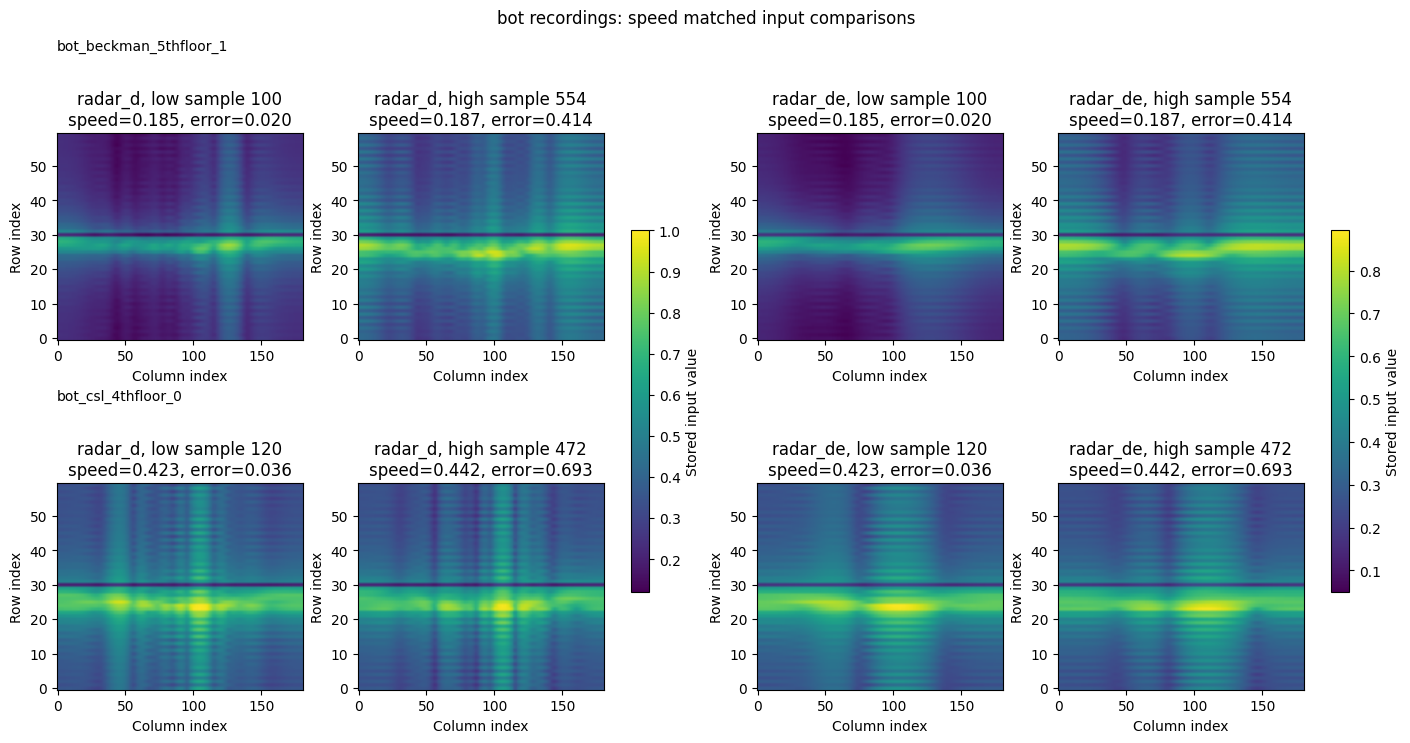

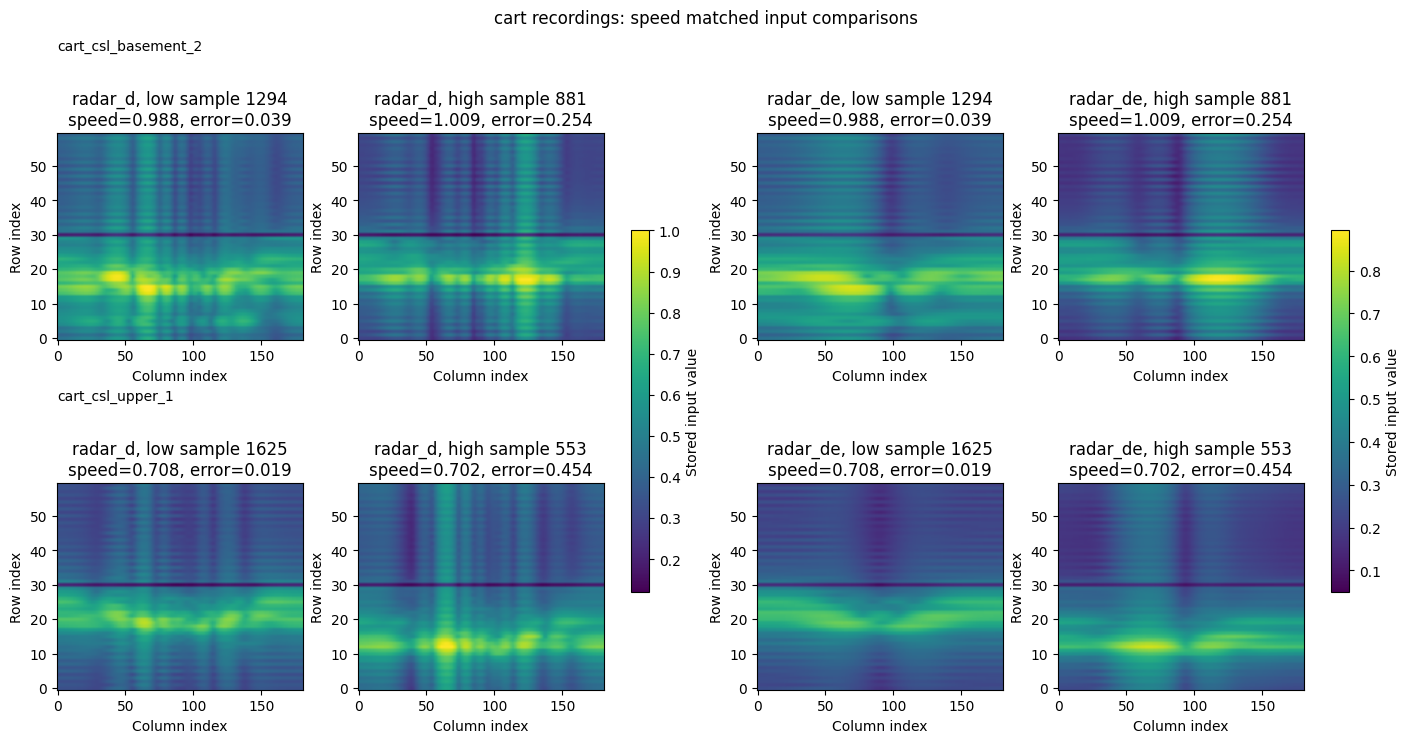

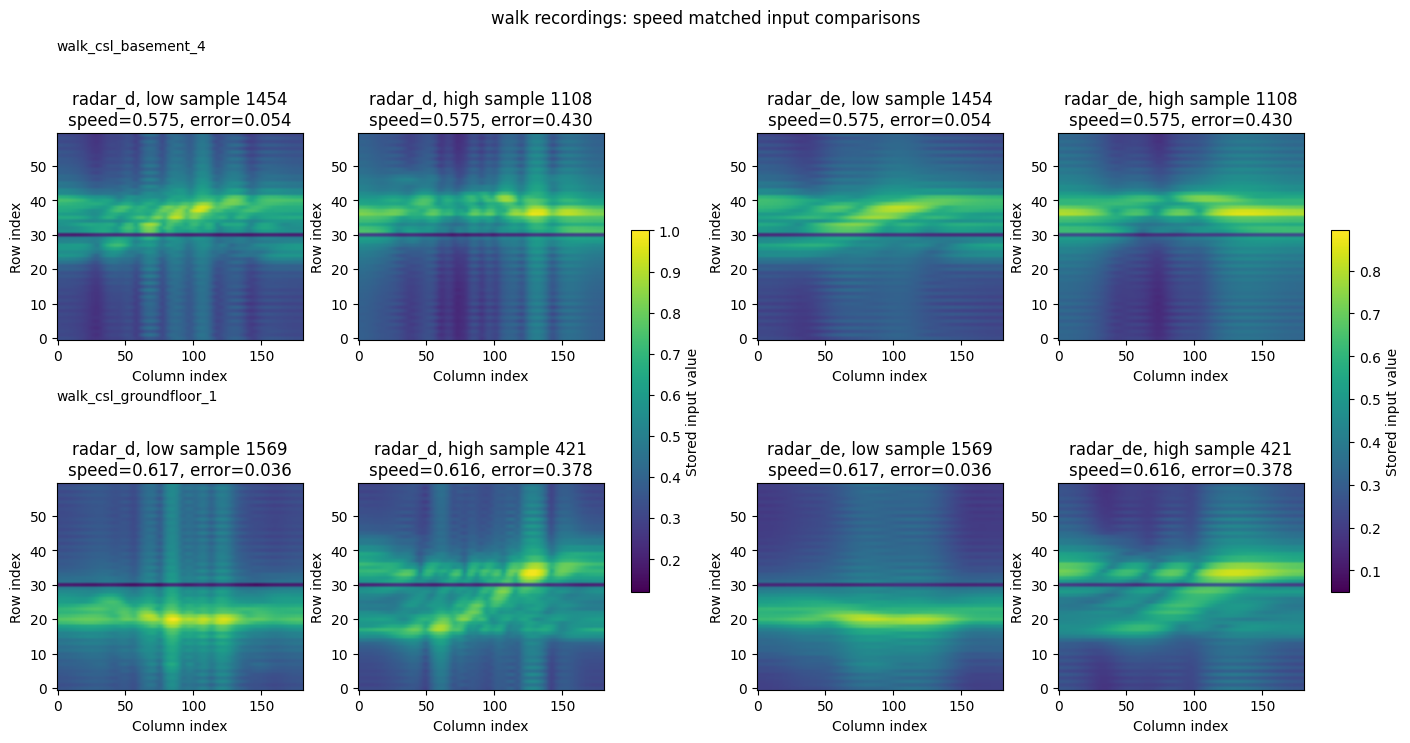

In [ ]:
pair_rows, feature_rows, selected_maps = [], [], {}
for rec, d in frames.items():
    low = d[d['vector_error'] <= d['vector_error'].quantile(0.25)]
    high = d[d['vector_error'] >= d['vector_error'].quantile(0.90)].sort_values('vector_error', ascending=False)
    chosen = None
    for hi in high.itertuples():
        tolerance = max(0.005, min(0.05, 0.10 * hi.speed))
        candidates = low[(low['speed'].sub(hi.speed).abs() <= tolerance)
                         & (low['sample'].sub(hi.sample).abs() >= 50)]
        if len(candidates):
            lo = candidates.loc[candidates['speed'].sub(hi.speed).abs().idxmin()]
            angle_gap = abs((lo['angle_deg'] - hi.angle_deg + 180) % 360 - 180)
            chosen = {'recording': rec, 'matched': True,
                      'low_sample': int(lo['sample']), 'high_sample': int(hi.sample),
                      'low_speed': lo['speed'], 'high_speed': hi.speed,
                      'low_error': lo['vector_error'], 'high_error': hi.vector_error,
                      'speed_gap': abs(lo['speed'] - hi.speed), 'tolerance': tolerance,
                      'angle_gap_degrees': angle_gap}
            break
    pair_rows.append(chosen if chosen else {'recording': rec, 'matched': False})
    with np.load(INPUTS / f'{rec}.npz', allow_pickle=False) as data:
        for channel in ['radar_d', 'radar_de']:
            images = data[channel]
            assert images.shape == (len(d), 1, 60, 181), (rec, channel, images.shape)
            assert np.isfinite(images).all(), (rec, channel)
            mean = pd.Series(images.mean(axis=(1, 2, 3)))
            spread = pd.Series(images.std(axis=(1, 2, 3)))
            feature_rows.append({
                'recording': rec, 'channel': channel,
                'intensity_mean_error_rho': mean.rank().corr(d['vector_error'].rank())
                    if mean.nunique() > 1 and d['vector_error'].nunique() > 1 else np.nan,
                'intensity_SD_error_rho': spread.rank().corr(d['vector_error'].rank())
                    if spread.nunique() > 1 and d['vector_error'].nunique() > 1 else np.nan,
            })
            if chosen:
                indices = [chosen['low_sample'], chosen['high_sample']]
                selected_maps[(rec, channel)] = images[indices, 0].copy()
            del images
radar_pairs = pd.DataFrame(pair_rows)
input_features = pd.DataFrame(feature_rows)
table('radar_speed_matched_pairs', radar_pairs)
table('input_feature_associations', input_features)

for group in COLOURS:
    recs = [r for r in RECORDINGS if r.startswith(group + '_')]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True)
    for channel_index, channel in enumerate(['radar_d', 'radar_de']):
        available = [v for (r, c), v in selected_maps.items() if c == channel]
        if not available:
            for ax in axes[:, 2 * channel_index:2 * channel_index + 2].flat:
                ax.text(0.5, 0.5, 'No speed match', ha='center', va='center')
                ax.set_axis_off()
            continue
        lower = min(float(v.min()) for v in available)
        upper = max(float(v.max()) for v in available)
        for row, rec in enumerate(recs):
            pair = radar_pairs.set_index('recording').loc[rec]
            if not pair['matched']:
                for ax in axes[row, 2 * channel_index:2 * channel_index + 2]:
                    ax.text(0.5, 0.5, 'No speed match', ha='center', va='center')
                    ax.set_axis_off()
                continue
            images = selected_maps[(rec, channel)]
            for j, label in enumerate(['low', 'high']):
                ax = axes[row, 2 * channel_index + j]
                image = ax.imshow(images[j], origin='lower', aspect='auto', cmap='viridis', vmin=lower, vmax=upper)
                ax.set(title=f"{channel}, {label} sample {int(pair[f'{label}_sample'])}\n"
                             f"speed={pair[f'{label}_speed']:.3f}, error={pair[f'{label}_error']:.3f}",
                       xlabel='Column index', ylabel='Row index')
                if j == 0 and channel_index == 0:
                    ax.text(0, 1.40, rec, transform=ax.transAxes, fontsize=10)
        colour_scale = plt.cm.ScalarMappable(norm=matplotlib.colors.Normalize(vmin=lower, vmax=upper), cmap='viridis')
        fig.colorbar(colour_scale, ax=axes[:, 2 * channel_index:2 * channel_index + 2].ravel().tolist(),
                     shrink=0.65, label='Stored input value')
    fig.suptitle(f'{group} recordings: speed matched input comparisons', y=1.04)
    figure(f'07_radar_{group}', fig)

## 9. Follow up: sharp changes in reference x velocity

We calculate the change in processed reference x velocity divided by the elapsed time since the previous frame. The current frame supplies the prediction error. This quantity is a reference change rate, rather than an independently measured physical acceleration.

Within each recording, lower change frames are at or below the median absolute change rate. Sharp changes exceed the 90th percentile, separated into increases and decreases. Remaining frames are intermediate. We also repeat the comparison at the 80th, 85th and 95th percentiles and compare the main conditions within reference speed quartiles. Counts reveal sparse comparisons.

The preprocessing audit in the supplied analysis found that reference velocity is derived from pose differences in local axes. The inspected filter can reuse the previous accepted velocity when the vector difference exceeds 0.5 stored units. Synchronization copies the nearest timestamp without an explicit maximum matching gap. These mechanisms can repeat reference values, but their contribution to any particular disagreement remains unresolved.

condition,recording,Lower change,Sharp increase,Sharp decrease
0,bot_beckman_5thfloor_1,0.0337,0.0832,0.0527
1,bot_csl_4thfloor_0,0.0629,0.1199,0.0300
2,cart_csl_basement_2,0.0594,0.1972,0.0583
3,cart_csl_upper_1,0.0651,0.1875,0.1042
4,walk_csl_basement_4,0.0421,0.0926,0.1095
5,walk_csl_groundfloor_1,0.0533,0.1457,0.0661


condition,recording,Lower change,Sharp increase,Sharp decrease
0,bot_beckman_5thfloor_1,899,88,92
1,bot_csl_4thfloor_0,892,90,89
2,cart_csl_basement_2,893,87,92
3,cart_csl_upper_1,892,88,91
4,walk_csl_basement_4,899,96,84
5,walk_csl_groundfloor_1,899,88,92


,recording,percentile_80,percentile_85,percentile_90,percentile_95
0,bot_beckman_5thfloor_1,1.9394,2.1592,2.4671,2.7830
1,bot_csl_4thfloor_0,1.6686,1.6804,1.9075,2.0411
2,cart_csl_basement_2,2.9259,3.1291,3.3193,3.4961
3,cart_csl_upper_1,2.3207,2.5972,2.8788,3.0544
4,walk_csl_basement_4,2.1040,2.1161,2.2011,2.9289
5,walk_csl_groundfloor_1,1.9198,2.0857,2.7313,3.2251


,recording,quartiles_with_both_conditions,quartiles_with_larger_increase_error,smallest_condition_count
0,bot_beckman_5thfloor_1,4,2,5
1,bot_csl_4thfloor_0,4,3,2
2,cart_csl_basement_2,4,4,2
3,cart_csl_upper_1,4,4,6
4,walk_csl_basement_4,4,3,9
5,walk_csl_groundfloor_1,4,4,7


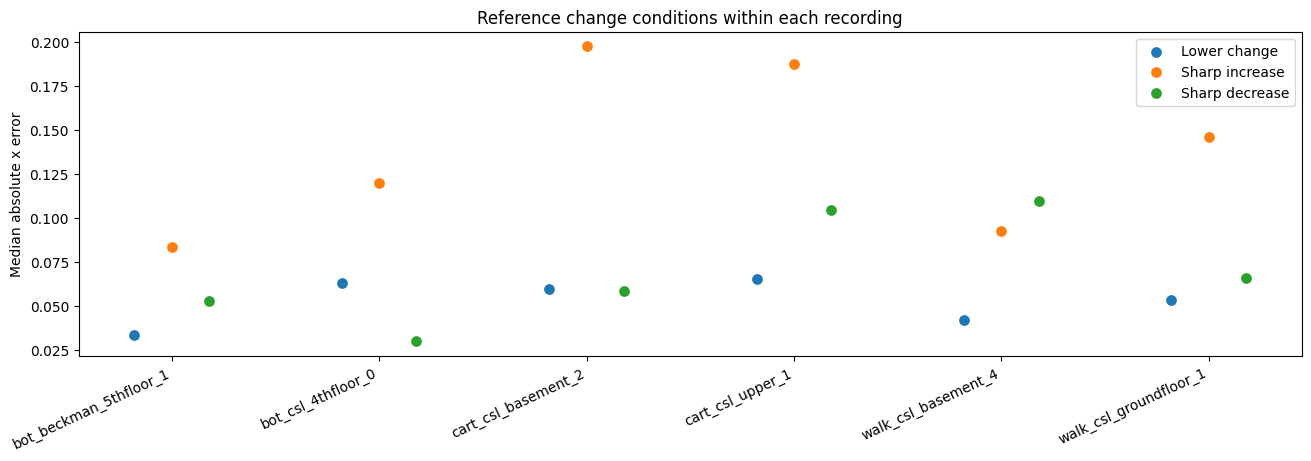

In [ ]:
condition_names = ['Lower change', 'Sharp increase', 'Sharp decrease']
change_rows, stratified_rows = [], []
for rec, d in frames.items():
    changes = d.iloc[1:].copy()
    changes['rate'] = np.diff(d['gt_x']) / np.diff(d['elapsed'])
    changes['absolute_x_error'] = changes['error_x'].abs()
    low_limit = changes['rate'].abs().quantile(0.5)
    for quantile in [0.80, 0.85, 0.90, 0.95]:
        threshold = changes['rate'].abs().quantile(quantile)
        changes['condition'] = np.select(
            [changes['rate'] > threshold, changes['rate'] < -threshold,
             changes['rate'].abs() <= low_limit],
            ['Sharp increase', 'Sharp decrease', 'Lower change'], default='Intermediate',
        )
        for name, part in changes.groupby('condition'):
            change_rows.append({
                'recording': rec, 'quantile': quantile, 'condition': name,
                'threshold': threshold, 'frames': len(part),
                'median_x_error': part['absolute_x_error'].median(),
                'median_speed': part['speed'].median(),
            })
        if quantile == 0.90:
            changes['speed_quartile'] = pd.qcut(changes['speed'], 4, labels=False, duplicates='drop')
            for (speed_bin, name), part in changes.groupby(['speed_quartile', 'condition'], observed=True):
                stratified_rows.append({
                    'recording': rec, 'speed_quartile': int(speed_bin) + 1, 'condition': name,
                    'frames': len(part), 'median_x_error': part['absolute_x_error'].median(),
                    'median_speed': part['speed'].median(),
                })
change_sensitivity = pd.DataFrame(change_rows)
speed_control = pd.DataFrame(stratified_rows)
main_change = change_sensitivity[change_sensitivity['quantile'] == 0.90]
change_values = main_change.pivot(index='recording', columns='condition', values='median_x_error').reindex(RECORDINGS)
change_counts = main_change.pivot(index='recording', columns='condition', values='frames').reindex(RECORDINGS).fillna(0)
table('reference_change_sensitivity', change_sensitivity, show=False)
table('reference_change_speed_quartiles', speed_control, show=False)
table('main_change_median_x_error', change_values.reindex(columns=condition_names).reset_index())
table('main_change_frame_counts', change_counts.reindex(columns=condition_names, fill_value=0).reset_index())

values = change_sensitivity.pivot(index=['recording', 'quantile'], columns='condition', values='median_x_error')
ratios = values.get('Sharp increase', pd.Series(dtype=float)) / values['Lower change'].replace(0, np.nan)
ratio_table = ratios.unstack('quantile').reindex(RECORDINGS)
ratio_table.columns = [f'percentile_{int(100 * q)}' for q in ratio_table.columns]
table('increase_to_lower_change_ratio', ratio_table.reset_index())

strata_rows = []
if len(speed_control):
    values = speed_control.pivot(index=['recording', 'speed_quartile'], columns='condition', values='median_x_error')
    counts = speed_control.pivot(index=['recording', 'speed_quartile'], columns='condition', values='frames')
    for rec in RECORDINGS:
        part = values.loc[rec].reindex(columns=['Lower change', 'Sharp increase']).dropna()
        matched_counts = counts.loc[rec].reindex(index=part.index, columns=['Lower change', 'Sharp increase'])
        strata_rows.append({
            'recording': rec, 'quartiles_with_both_conditions': len(part),
            'quartiles_with_larger_increase_error': int((part['Sharp increase'] > part['Lower change']).sum()),
            'smallest_condition_count': int(matched_counts.min().min()) if len(part) else 0,
        })
strata_check = pd.DataFrame(strata_rows)
table('speed_quartile_comparison', strata_check)

fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
for offset, name in zip([-0.18, 0, 0.18], condition_names):
    ax.scatter(np.arange(6) + offset, change_values.reindex(columns=[name])[name], label=name, s=45)
ax.set_xticks(np.arange(6), RECORDINGS, rotation=25, ha='right')
ax.set(ylabel='Median absolute x error', title='Reference change conditions within each recording')
ax.legend()
figure('08_reference_change_comparison', fig)

## 10. Findings and limitations

The following interpretation is calculated from this execution. The quantitative findings should be read together with the plots and the stated sample coverage.

In [ ]:
increase = change_values.reindex(columns=['Lower change', 'Sharp increase']).dropna()
decrease = change_values.reindex(columns=['Lower change', 'Sharp decrease']).dropna()
ratios_main = increase['Sharp increase'] / increase['Lower change'].replace(0, np.nan)
increase_count = int((increase['Sharp increase'] > increase['Lower change']).sum())
decrease_count = int((decrease['Sharp decrease'] > decrease['Lower change']).sum())
exceptions = decrease.index[decrease['Sharp decrease'] <= decrease['Lower change']].tolist()
counterexamples = ', '.join(exceptions) if exceptions else 'none in this selected scope'
component_pivot = components.pivot(index='recording', columns='axis', values='MAE')
larger_x = int((component_pivot['x'] > component_pivot['y']).sum())
group_order = group_summary.sort_values('median_of_recording_medians')['group'].tolist()
matched_count = int(radar_pairs['matched'].sum())
intensity_rho = input_features['intensity_mean_error_rho'].dropna()
rho_text = (f'{intensity_rho.min():.3f} to {intensity_rho.max():.3f}'
            if len(intensity_rho) else 'undefined because intensity is constant')
tail_ranges = []
for threshold, part in tails.groupby('threshold'):
    tail_ranges.append(f"Above {threshold:g} units, frame percentages range from "
                       f"{part['percent_above'].min():.1f}% to {part['percent_above'].max():.1f}%.")

findings = f"""
### Motion changes

At the main threshold, sharp increases in processed reference x velocity have a larger median absolute x error than lower change frames in **{increase_count} of {len(increase)} recordings**. The ratios range from **{ratios_main.min():.2f} to {ratios_main.max():.2f}**. Sharp decreases have a larger median in {decrease_count} of {len(decrease)} recordings. Counterexamples to a larger decrease error are {counterexamples}. We therefore distinguish positive changes from negative changes. The sensitivity and speed quartile tables show where this comparison persists and where coverage is sparse. Reference values enter both the condition definition and the error, so reference noise can contribute to this association.

### Direction and timing

For {ANCHOR}, the sector with the largest median error is **{focus['angle_degrees']} degrees**. It contains {int(focus['frames'])} frames, has median vector error {focus['median_error']:.4f}, and its largest contiguous interval accounts for **{100 * focus['largest_run_fraction']:.1f}%** of those frames, from sample {start} to {end}. This makes the temporal trace essential: many neighbouring observations can describe one sustained disagreement. Reusing the same interval at several speed cutoffs is not independent confirmation of a general directional weakness. Prediction delay and the cause of the disagreement remain unresolved.

### Error magnitude and recording coverage

X MAE exceeds y MAE in {larger_x} of {len(component_pivot)} recordings. Component movement ranges differ, so this does not by itself rank the difficulty of x and y prediction. {' '.join(tail_ranges)} The tail table also reports contiguous runs, separating frame frequency from temporal concentration. Filename groups ordered by median recording error are {', '.join(group_order)}. This ranking describes these two recordings per group; it cannot isolate a physical platform effect from speed, direction or scene.

### Radar input comparisons

The selection rule found valid speed matches in {matched_count} of {len(RECORDINGS)} recordings. The pair table reports the remaining direction differences. Across all frames, mean intensity correlations with vector error range from {rho_text}. These coefficients test a simple input property more broadly than selected images, but neither a correlation nor a visible band establishes what the network uses internally. The heatmaps are examples with explicit controls and limits, rather than evidence of one universal cause of error.
"""
findings = findings.replace('-', '−')
display(Markdown(findings))
(OUT / 'findings.md').write_text(findings, encoding='utf-8')


### Motion changes

At the main threshold, sharp increases in processed reference x velocity have a larger median absolute x error than lower change frames in **6 of 6 recordings**. The ratios range from **1.91 to 3.32**. Sharp decreases have a larger median in 4 of 6 recordings. Counterexamples to a larger decrease error are bot_csl_4thfloor_0, cart_csl_basement_2. We therefore distinguish positive changes from negative changes. The sensitivity and speed quartile tables show where this comparison persists and where coverage is sparse. Reference values enter both the condition definition and the error, so reference noise can contribute to this association.

### Direction and timing

For bot_beckman_5thfloor_1, the sector with the largest median error is **−135 to −90 degrees**. It contains 15 frames, has median vector error 0.4048, and its largest contiguous interval accounts for **93.3%** of those frames, from sample 546 to 559. This makes the temporal trace essential: many neighbouring observations can describe one sustained disagreement. Reusing the same interval at several speed cutoffs is not independent confirmation of a general directional weakness. Prediction delay and the cause of the disagreement remain unresolved.

### Error magnitude and recording coverage

X MAE exceeds y MAE in 5 of 6 recordings. Component movement ranges differ, so this does not by itself rank the difficulty of x and y prediction. Above 0.1 units, frame percentages range from 11.9% to 45.7%. Above 0.2 units, frame percentages range from 1.1% to 8.7%. The tail table also reports contiguous runs, separating frame frequency from temporal concentration. Filename groups ordered by median recording error are bot, cart, walk. This ranking describes these two recordings per group; it cannot isolate a physical platform effect from speed, direction or scene.

### Radar input comparisons

The selection rule found valid speed matches in 6 of 6 recordings. The pair table reports the remaining direction differences. Across all frames, mean intensity correlations with vector error range from 0.002 to 0.274. These coefficients test a simple input property more broadly than selected images, but neither a correlation nor a visible band establishes what the network uses internally. The heatmaps are examples with explicit controls and limits, rather than evidence of one universal cause of error.


2401

### What these findings support

This investigation connects error patterns to motion conditions, sample coverage and temporal intervals rather than relying only on an overall score. All six recordings are selected from one test split and use one checkpoint. Temporal dependence, processed reference values and unverified physical calibration limit broader conclusions. Earlier input preprocessing provenance was not fully captured; checking prediction alignment does not reconstruct it. The full input archive digest is not recomputed here.

For Phase II, we propose comparing input saliency maps with PCA of learned features, using the sustained disagreement and speed matched cases as a common starting point. We would check whether an explanation repeats across recordings and retain counterexamples. These are proposed investigations, rather than completed explanations of the model.

### Sources

Original method: *Radarize: Enhancing Radar SLAM with Generalizable Doppler Based Odometry*, Emerson Sie, Xinyu Wu, Heyu Guo and Deepak Vasisht, MobiSys 2024.

1. [Radarize implementation](https://github.com/ConnectedSystemsLab/radarize_ae/tree/cbcb6439b89c068d86a424215ee61edc925191ae)
2. [Official evaluation files and dataset](https://zenodo.org/records/11093859)
3. [Research paper](https://arxiv.org/abs/2311.11260)

The supplied notebook records the completed inference and preprocessing audit. This version reuses its saved evaluations and recalculates the analysis. Reference processing statements refer to the inspected revision cited above.

In [ ]:
run_record = {
    'created_utc': STAMP, 'recordings': RECORDINGS, 'frames': len(combined),
    'source_commit': SOURCE_COMMIT, 'prediction_metadata': provenance,
    'input_directory': str(INPUTS), 'prediction_directory': str(PREDICTIONS),
    'units': 'stored velocity units', 'platform_mapping': 'inferred from filename only',
    'scope': 'Evaluation of completed saved predictions; no new inference in this notebook',
    'validation': 'Prediction digests, shared evaluation identity, timestamps and references checked',
    'input_archive_digest_rechecked': False,
    'python': sys.version, 'numpy': np.__version__, 'pandas': pd.__version__,
    'matplotlib': matplotlib.__version__,
    'ai_assistance': 'Code editing, additional evaluation and interpretation',
}
(OUT / 'run_record.json').write_text(json.dumps(run_record, indent=2), encoding='utf-8')
print('Analysis complete. Figures and tables:', OUT)
print('Save or download this notebook with its outputs before submission.')

Analysis complete. Figures and tables: /content/drive/MyDrive/RadaVis/results/main_0/phase1_submission/20261026T093910_289317Z
Save or download this notebook with its outputs before submission.


This notebook supplies Pair B's Phase I analysis. The group midpoint also requires the other pair's code, the AI interaction record and the shared progress video of up to five minutes. The public repository must include the completed team and workload files specified in Moodle.